# Stage 1: "Is there a problem?" classifier, v1.2 data (Brandon)

**What this notebook does, in plain words:** it teaches a pretrained image model (EfficientNet-B0) to answer one
question about a mouth photo: *does it show any of the five conditions, or does it look healthy?*
This is stage 1 of the two-stage plan. Stage 2 (YOLO) then finds **where** the problem is and **what** it is.

**Data: the cleaned v1.2 pool** (`datasets/oral_datasetv1.2/pool`, built by `dataset_v12/build_v1_2.py` and split by
`dataset_v12/split_v1_2.py`). Differences from v1.1:
- Roboflow photos are the **originals** (v1.1 had 640x640 stretched copies plus 3x augmented copies).
- Gingivitis was removed; the 5 conditions are Calculus, Caries, Hypodontia, Mouth ulcer, Tooth discolouration.
- Copies across sources were removed (including mirrored copies of Roboflow photos inside kaggle_oral).
- Every photo was processed the same way (fit to 640, grey padding, JPEG 90, no EXIF). **This notebook also cuts
  the grey padding off**, so the model can't use how much padding a photo has as a clue.
- The split puts healthy AND problem photos of every mixed source (DentalAI, Zenodo, Kaggle, web) into val and test.

**The exams:**
- `val_fair` / `test_fair`: val / test photos from the mixed sources. The source gives nothing away, so these are the
  **honest** scores. The best epoch and the decision threshold are chosen on `val_fair`. **Quote `test_fair` first.**
- `test` (all): includes Roboflow (all problem) and Mendeley (all healthy) photos, where the photo's style still hints
  at the answer. Reported for comparison only.

**Run it:** pick the `.venv-train` kernel and Run All. Set the environment variable `ISSUE_SMOKE=1` for a 2-minute check
on a few hundred photos before the real run.


## 0. Setup

In [1]:
import json, os, random, re, time, copy
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision as tv
from PIL import Image
from sklearn.metrics import confusion_matrix, roc_auc_score
from torchvision.transforms import v2
from tqdm.auto import tqdm

from issue_data import CORRUPTIONS, OralDS, make_cache_nopad

print("torch", torch.__version__, "| torchvision", tv.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU will be very slow)")

D:\nyp\Sem 2\AI Innovation Deep learning\.venv-train\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.7.1+cu126 | torchvision 0.22.1+cu126


GPU: NVIDIA GeForce GTX 1050 Ti with Max-Q Design


## 1. Settings  ← the only cell you normally edit

`CACHE_SIDE`: photos are shrunk once to at most this many pixels on the long side and saved next to the dataset.
The originals go up to 6720 px, and decoding those every epoch would make training many times slower.

In [2]:
NB_DIR = Path.cwd()
REPO = next(p for p in [NB_DIR, *NB_DIR.parents] if (p / "shared" / "conditions.yaml").exists())
DATA_DIR = Path(os.environ.get("ORAL_DATA", REPO.parent / "datasets" / "oral_datasetv1.2" / "pool"))
CACHE_SIDE = 288
CACHE_DIR = DATA_DIR.parent / f"cache_{CACHE_SIDE}_nopad"

SMOKE = os.environ.get("ISSUE_SMOKE") == "1"   # quick end-to-end check on a small sample
EXPERIMENT = "B2_effb0_issue_v12" + ("_smoke" if SMOKE else "")

IMG_SIZE = 224
BATCH = 32            # fits a 4 GB GPU with mixed precision
HEAD_EPOCHS = 1       # phase 1: train only the new last layer
EPOCHS = 2 if SMOKE else 15   # total epochs including phase 1
LR_HEAD, LR = 1e-3, 3e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 4          # stop if val_fair AUC hasn't improved for this many epochs
TARGET_RECALL = 0.95  # pick the decision threshold so val_fair recall on "issue" is at least this
UNSURE_BELOW = 0.65   # calibrated confidence under this -> "not sure, see a dentist"
NUM_WORKERS = 4
MIXED_SOURCES = ["zenodo", "dentalai", "kaggle_oral", "external_clean"]   # sources with both classes
SEED = 42

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet, as the backbone was trained
CONDITIONS = (DATA_DIR / "classes.txt").read_text().split()

OUT_DIR = REPO / "models" / "classifier" / "results" / "Brandon"
WEIGHTS_DIR = REPO / "models" / "classifier" / "weights" / "Brandon"
FIG_DIR = OUT_DIR / "figures"
for d in (OUT_DIR, WEIGHTS_DIR, FIG_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("data:", DATA_DIR, "| classes:", CONDITIONS, "| smoke run:", SMOKE, "| device:", device)


data: D:\nyp\Sem 2\AI Innovation Deep learning\datasets\oral_datasetv1.2\pool | classes: ['Calculus', 'Caries', 'Hypodontia', 'Mouth_Ulcer', 'Tooth_Discoloration'] | smoke run: False | device: cuda


## 2. Load the labels and look at the split

Each row of `pool.csv` is one photo. The split was made by `dataset_v12/split_v1_2.py`: whole groups (copies of a photo, all
photos of one Zenodo patient) go to one split, and each source's healthy and problem photos are split separately.
`label_by` says who decided the labels: `person`, `qwen`, or a mix.


In [3]:
df = pd.read_csv(DATA_DIR / "pool.csv")
df["src"] = [str(DATA_DIR / p) for p in df["image"]]
df["cache"] = [str(CACHE_DIR / (Path(p).stem + ".jpg")) for p in df["image"]]
df["person_only"] = df["label_by"].eq("person")
df["fair"] = df["dataset"].isin(MIXED_SOURCES)
df["labels"] = df[CONDITIONS].apply(lambda r: "|".join(c for c in CONDITIONS if r[c]) or "Normal", axis=1)
assert df["split"].isin(["train", "val", "test"]).all(), "run dataset_v12/split_v1_2.py first"

if SMOKE:   # 150 photos per (split, fair, class) is enough to check every cell runs
    idx = []
    for _, g in df.groupby(["split", "fair", "has_issue"]):
        idx += list(g.sample(min(len(g), 150), random_state=SEED).index)
    df = df.loc[idx].reset_index(drop=True)

kind = df["has_issue"].map({0: "healthy", 1: "issue"})
print(len(df), "photos")
display(pd.crosstab(df["split"], kind, margins=True))
print("by source (the fair exams are the mixed-source rows):")
display(pd.crosstab(df["dataset"], [df["split"], kind]))
display(pd.crosstab(df["split"], df["label_by"]))


19416 photos


has_issue,healthy,issue,All
split,,,
test,999,2047,3046
train,3804,9225,13029
val,1021,2320,3341
All,5824,13592,19416


by source (the fair exams are the mixed-source rows):


split                 test         train           val      
has_issue          healthy issue healthy issue healthy issue
dataset                                                     
dentalai               231   224     460  1045     229   227
external_clean          15    48      29   218      15    47
kaggle_oral             59   100     118   465      59   100
mendeley_noncaries     680     0    3167     0     700     0
roboflow_oral            0  1344       0  6270       0  1344
zenodo                  14   331      30  1227      18   602

label_by,person,person (caries) + qwen (other conditions),person (condition) + qwen (boxes),qwen
split,,,,
test,1403,800,97,746
train,6388,2762,444,3435
val,1403,1076,95,767


### Leakage check

A test set only means something if the model has never seen those photos in any form. Every copy of a photo
(`group`) and every photo of one Zenodo patient stay in one split. This cell double-checks that no group or identical
file (`uid` = md5 of the original file) is in both train and val/test.


In [4]:
for col in ("group", "uid"):
    seen_in_train = set(df.loc[df.split == "train", col].dropna())
    in_eval = set(df.loc[df.split != "train", col].dropna())
    print(f"{col}: {len(seen_in_train & in_eval)} shared between train and val/test (should be 0)")


group: 0 shared between train and val/test (should be 0)
uid: 0 shared between train and val/test (should be 0)


### Cheat check: can a "dumb" rule pass the exam?

Before training, we try to pass each exam **without looking at the teeth**: a small decision tree only sees the
photo's original width, height and shape. If that already scores high, the exam can be passed by recognising the
kind of photo, so a high model score there proves little. We want the fair exams to be close to 0.5 (a coin flip).


In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import balanced_accuracy_score

feat = lambda f: np.c_[f.orig_w, f.orig_h, f.orig_w / f.orig_h]
tr = df[df.split == "train"]
cheat = DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=SEED).fit(feat(tr), tr.has_issue)
cheat_scores = {}
for name, f in {"val": df[df.split == "val"], "val_fair": df[(df.split == "val") & df.fair],
                "test": df[df.split == "test"], "test_fair": df[(df.split == "test") & df.fair]}.items():
    cheat_scores[name] = balanced_accuracy_score(f.has_issue, cheat.predict(feat(f)))
display(pd.Series(cheat_scores, name="balanced accuracy of the size-only rule").round(3))


val          0.870
val_fair     0.596
test         0.866
test_fair    0.582
Name: balanced accuracy of the size-only rule, dtype: float64

### A few photos from each class

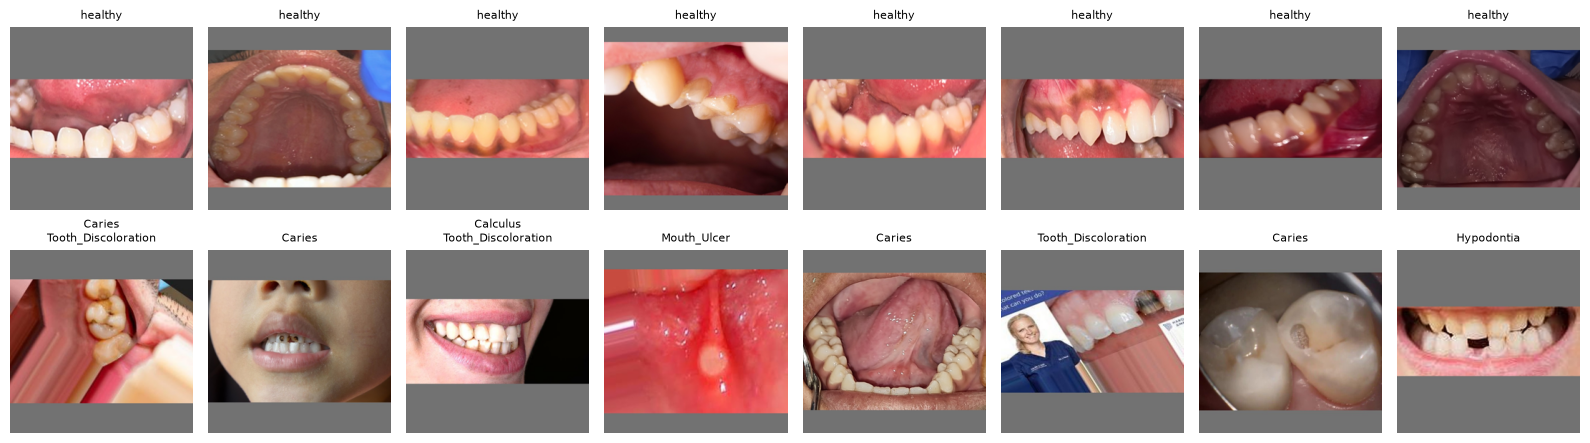

In [6]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for r, (lab, name) in enumerate([(0, "healthy"), (1, "issue")]):
    rows = df[(df.split == "train") & (df.has_issue == lab)].sample(8, random_state=SEED)
    for ax, (_, row) in zip(axes[r], rows.iterrows()):
        with Image.open(row.src) as im:
            im.thumbnail((256, 256)); ax.imshow(im.convert("RGB"))
        ax.set_title(name if lab == 0 else row["labels"].replace("|", "\n"), fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Cut off the padding and shrink the photos once (cache)

Runs in parallel and skips files already cached, so a second run takes seconds. Unreadable photos are dropped and counted.

In [7]:
t0 = time.time()
jobs = list(zip(df.src, df.cache, df.orig_w, df.orig_h))
with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    ok = list(tqdm(ex.map(lambda a: make_cache_nopad(a[0], a[1], CACHE_SIDE, int(a[2]), int(a[3])), jobs),
                   total=len(df), desc="caching"))
df = df[np.array(ok)].reset_index(drop=True)
print(f"{len(ok) - sum(ok)} unreadable photos dropped; {len(df)} kept; {time.time() - t0:.0f}s")

train_df, val_df, test_df = (df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test"))
val_fair_df = val_df[val_df.fair].reset_index(drop=True)
fair_df = test_df[test_df.fair].reset_index(drop=True)      # test_fair


caching:   0%|          | 0/19416 [00:00<?, ?it/s]

caching:   0%|          | 52/19416 [00:00<00:40, 480.41it/s]

caching:   1%|          | 101/19416 [00:00<00:41, 460.53it/s]

caching:   1%|          | 148/19416 [00:00<00:46, 416.40it/s]

caching:   1%|          | 190/19416 [00:00<00:50, 380.42it/s]

caching:   1%|          | 229/19416 [00:00<00:53, 360.95it/s]

... (552 outputs left out)

caching: 100%|█████████▉| 19339/19416 [01:00<00:00, 327.54it/s]

caching: 100%|█████████▉| 19375/19416 [01:00<00:00, 324.55it/s]

caching: 100%|██████████| 19416/19416 [01:00<00:00, 320.60it/s]

0 unreadable photos dropped; 19416 kept; 61s


## 4. Feed the photos to the model

**Training photos** get random small changes (crop, flip, rotation, colour) so the model sees more variety and can't
memorise exact pixels. The crop keeps at least 70% of the photo so a small lesion is rarely cut out, and it also changes the shape a little,
so the photo's shape is less useful as a clue.
**Val/test photos** are only resized.

In [8]:
train_tf = v2.Compose([
    v2.ToImage(),
    v2.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.75, 1.33), antialias=True),
    v2.RandomHorizontalFlip(),
    v2.RandomRotation(15),
    v2.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.02),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])
eval_tf = v2.Compose([
    v2.ToImage(),
    v2.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])


def loader(frame, tf, shuffle=False, corrupt=None):
    ds = OralDS(frame.cache, frame.has_issue.astype(int), tf, corrupt)
    return torch.utils.data.DataLoader(ds, batch_size=BATCH, shuffle=shuffle, num_workers=NUM_WORKERS,
                                       pin_memory=device.type == "cuda", persistent_workers=NUM_WORKERS > 0)


train_dl, val_dl, test_dl = loader(train_df, train_tf, shuffle=True), loader(val_df, eval_tf), loader(test_df, eval_tf)
val_fair_dl, fair_dl = loader(val_fair_df, eval_tf), loader(fair_df, eval_tf)

## 5. Handle the imbalance

There are about 2 "issue" photos for every healthy one. A lazy model could say "issue" every time and look 67% right.
**Class weights** make a mistake on the rarer class cost more.

In [9]:
counts = train_df.has_issue.value_counts().sort_index()
class_w = torch.tensor((len(train_df) / (2 * counts)).values, dtype=torch.float32)
print("train counts (healthy, issue):", counts.tolist(), "| class weights:", [round(float(w), 2) for w in class_w])

train counts (healthy, issue): [3804, 9225] | class weights: [1.71, 0.71]


## 6. Build the model

A **pre-trained eye** (EfficientNet-B0, trained on ImageNet's 1.3 M everyday photos) plus a **new 2-way last layer**
(healthy / issue). EfficientNet-B0 is small (4 M parameters) and was among the best in Daniel's 12-backbone comparison.

In [10]:
def build_model():
    m = tv.models.efficientnet_b0(weights=tv.models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, 2)
    return m


model = build_model().to(device)
criterion = nn.CrossEntropyLoss(weight=class_w.to(device))
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parameters")

4.0 M parameters


## 7. Train

- **Phase 1** (`HEAD_EPOCHS`): the pre-trained eye is frozen and only the new layer learns.
- **Phase 2**: everything is unlocked and fine-tuned with a smaller learning rate that slowly decreases (cosine schedule).
- After every epoch we score the validation sets. The best epoch is the one with the highest **val_fair** ROC-AUC
  (the honest quiz), and training stops early if it hasn't improved for `PATIENCE` epochs.

Mixed precision (`autocast`) halves the memory use so a batch of 32 fits on a 4 GB GPU.

In [11]:
@torch.no_grad()
def predict_logits(model, dl):
    model.eval()
    out, ys = [], []
    for x, y in dl:
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            out.append(model(x.to(device, non_blocking=True)).float().cpu())
        ys.append(y)
    return torch.cat(out), torch.cat(ys).numpy()


def p_issue(logits, T=1.0):
    return (logits / T).softmax(1)[:, 1].numpy()


def set_phase(head_only):
    for p in model.features.parameters():
        p.requires_grad = not head_only
    params = [p for p in model.parameters() if p.requires_grad]
    return torch.optim.AdamW(params, lr=LR_HEAD if head_only else LR, weight_decay=WEIGHT_DECAY)


scaler = torch.amp.GradScaler(device.type, enabled=device.type == "cuda")
history, best_auc, best_state, bad_epochs = [], -1.0, None, 0
opt = set_phase(head_only=True)
sched = None

for epoch in range(1, EPOCHS + 1):
    if epoch == HEAD_EPOCHS + 1:
        opt = set_phase(head_only=False)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(1, (EPOCHS - HEAD_EPOCHS) * len(train_dl)))
    model.train()
    t0, total, n = time.time(), 0.0, 0
    for x, y in tqdm(train_dl, desc=f"epoch {epoch}/{EPOCHS}", leave=False):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            loss = criterion(model(x), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        if sched is not None:
            sched.step()
        total += loss.item() * len(y); n += len(y)

    logits, yv = predict_logits(model, val_dl)
    pv = p_issue(logits)
    val_loss = nn.functional.cross_entropy(logits, torch.as_tensor(yv), weight=class_w).item()
    auc = roc_auc_score(yv, pv)
    lf, yf = predict_logits(model, val_fair_dl)
    fair_auc = roc_auc_score(yf, p_issue(lf))
    rec_issue = ((pv >= 0.5) & (yv == 1)).sum() / max(1, (yv == 1).sum())
    rec_healthy = ((pv < 0.5) & (yv == 0)).sum() / max(1, (yv == 0).sum())
    history.append(dict(epoch=epoch, train_loss=total / n, val_loss=val_loss, val_auc=auc, val_fair_auc=fair_auc,
                        val_recall_issue=rec_issue, val_recall_healthy=rec_healthy, minutes=(time.time() - t0) / 60))
    print(f"epoch {epoch}: train loss {total / n:.3f} | val loss {val_loss:.3f} | val AUC {auc:.4f} | val_fair AUC {fair_auc:.4f} | "
          f"recall issue {rec_issue:.3f} healthy {rec_healthy:.3f} | {(time.time() - t0) / 60:.1f} min")

    if fair_auc > best_auc:
        best_auc, best_epoch, bad_epochs = fair_auc, epoch, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE and epoch > HEAD_EPOCHS:
            print(f"stopping early: no val_fair AUC gain for {PATIENCE} epochs")
            break

model.load_state_dict(best_state)
hist = pd.DataFrame(history)
print(f"best epoch {best_epoch}, val_fair AUC {best_auc:.4f}")

epoch 1/15:   0%|          | 0/408 [00:00<?, ?it/s]

epoch 1/15:   0%|          | 1/408 [00:27<3:03:50, 27.10s/it]

epoch 1/15:   0%|          | 2/408 [00:27<1:15:55, 11.22s/it]

epoch 1/15:   1%|          | 4/408 [00:27<28:35,  4.25s/it]  

epoch 1/15:   1%|▏         | 6/408 [00:27<15:17,  2.28s/it]

epoch 1/15:   2%|▏         | 8/408 [00:27<09:19,  1.40s/it]

... (3,244 outputs left out)

epoch 8/15: 100%|█████████▉| 406/408 [04:42<00:01,  1.52it/s]

epoch 8/15: 100%|█████████▉| 407/408 [04:42<00:00,  1.52it/s]

epoch 8/15: 100%|██████████| 408/408 [04:43<00:00,  1.99it/s]

epoch 8: train loss 0.034 | val loss 0.275 | val AUC 0.9832 | val_fair AUC 0.9207 | recall issue 0.975 healthy 0.912 | 5.1 min
stopping early: no val_fair AUC gain for 4 epochs
best epoch 4, val_fair AUC 0.9305


### Did it learn? (training curves)

Train and val loss should both go down. If train keeps falling while val climbs, the model is memorising (overfitting);
early stopping keeps the epoch before that happens.

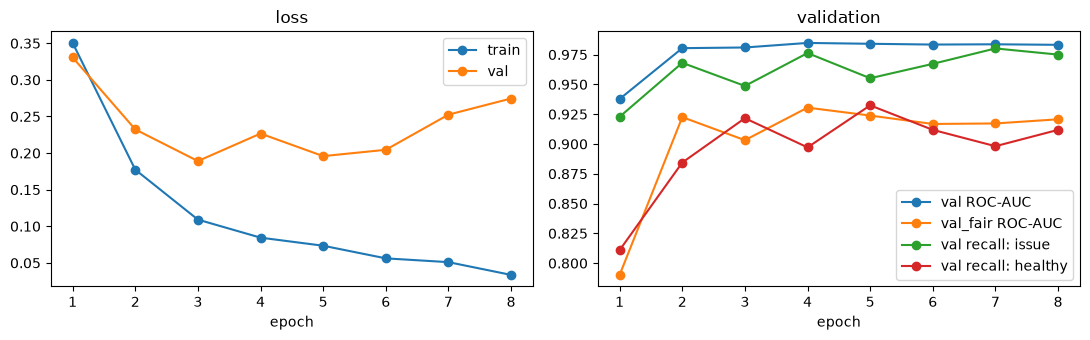

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(hist.epoch, hist.train_loss, "o-", label="train"); ax[0].plot(hist.epoch, hist.val_loss, "o-", label="val")
ax[0].set_title("loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist.epoch, hist.val_auc, "o-", label="val ROC-AUC")
ax[1].plot(hist.epoch, hist.val_fair_auc, "o-", label="val_fair ROC-AUC")
ax[1].plot(hist.epoch, hist.val_recall_issue, "o-", label="val recall: issue")
ax[1].plot(hist.epoch, hist.val_recall_healthy, "o-", label="val recall: healthy")
ax[1].set_title("validation"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / f"{EXPERIMENT}_curves.png", dpi=120); plt.show()

## 8. Calibrate, then choose the decision threshold (on validation only)

- **Temperature scaling**: raw model confidences tend to be over-confident. One number `T` is fitted on the validation
  set so that "80% sure" really means right about 80% of the time. This is what lets the app show honest probabilities.
- **Threshold**: by default a photo is "issue" when its probability is ≥ 0.5. For a screening tool, missing a problem is
  worse than a false alarm (a dentist visit), so the threshold is lowered until **val_fair** recall on "issue" reaches
  `TARGET_RECALL`.
- **Not sure**: when the calibrated confidence is below `UNSURE_BELOW`, the app should say "not sure, see a dentist"
  instead of giving an answer.

The test set is not touched in this step, so the test score stays an honest exam.

In [13]:
val_logits, yv = predict_logits(model, val_dl)

log_T = torch.zeros(1, requires_grad=True)
opt_T = torch.optim.LBFGS([log_T], lr=0.1, max_iter=100)
def closure():
    opt_T.zero_grad()
    loss = nn.functional.cross_entropy(val_logits / log_T.exp(), torch.as_tensor(yv))
    loss.backward()
    return loss
opt_T.step(closure)
T = float(log_T.exp())

pv = p_issue(val_logits, T)
vf_logits, yvf = predict_logits(model, val_fair_dl)
pvf = p_issue(vf_logits, T)
threshold = float(np.quantile(pvf[yvf == 1], 1 - TARGET_RECALL))
threshold = min(threshold, 0.5)   # never make the model *less* sensitive than the default
print(f"temperature T = {T:.3f} | decision threshold = {threshold:.3f}")

temperature T = 1.773 | decision threshold = 0.500


## 9. Final exam: the test set

Four scores:
- **test_fair**: test photos from the mixed sources, where the photo's source doesn't reveal the answer. **Quote this one first.**
- **all test photos**: also includes Roboflow (all problem) and Mendeley (all healthy) photos.
- **person-labelled test photos only** (no Qwen labels). If this is close to "all", Qwen's labels are fine.
- **all test at threshold 0.5**: the same, without the lowered threshold, to show what the threshold changes.


In [14]:
def scores(y, p, t, conf_floor=UNSURE_BELOW):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    div = lambda a, b: a / b if b else float("nan")
    conf = np.maximum(p, 1 - p)
    sure = conf >= conf_floor
    return dict(
        n=len(y), n_issue=int((y == 1).sum()), n_healthy=int((y == 0).sum()),
        accuracy=div(tp + tn, len(y)),
        balanced_accuracy=np.nanmean([div(tp, tp + fn), div(tn, tn + fp)]),
        recall_issue=div(tp, tp + fn), recall_healthy=div(tn, tn + fp),
        precision_issue=div(tp, tp + fp),
        f1_issue=div(2 * tp, 2 * tp + fp + fn),
        roc_auc=roc_auc_score(y, p) if len(set(y)) > 1 else float("nan"),
        unsure_rate=float(1 - sure.mean()),
        accuracy_when_sure=div(int(((pred == y) & sure).sum()), int(sure.sum())),
        tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn),
    )


test_logits, yt = predict_logits(model, test_dl)
pt = p_issue(test_logits, T)
test_df["p_issue"] = pt
test_df["pred"] = (pt >= threshold).astype(int)
fair_logits, ym = predict_logits(model, fair_dl)
pm = p_issue(fair_logits, T)
fair_df["p_issue"] = pm
fair_df["pred"] = (pm >= threshold).astype(int)

person = test_df.person_only.values
results = {
    "val": scores(yv, pv, threshold),
    "val_fair": scores(yvf, pvf, threshold),
    "test_fair": scores(ym, pm, threshold),
    "test_all": scores(yt, pt, threshold),
    "test_person_only": scores(yt[person], pt[person], threshold),
    "test_all_at_0.5": scores(yt, pt, 0.5),
}
summary = pd.DataFrame(results).T
display(summary[["n", "n_issue", "n_healthy", "recall_issue", "recall_healthy", "balanced_accuracy",
                 "precision_issue", "f1_issue", "roc_auc", "unsure_rate", "accuracy_when_sure"]].round(3))

,n,n_issue,n_healthy,recall_issue,recall_healthy,balanced_accuracy,precision_issue,f1_issue,roc_auc,unsure_rate,accuracy_when_sure
val,3341.0,2320.0,1021.0,0.976,0.897,0.937,0.956,0.966,0.985,0.045,0.970
val_fair,1297.0,976.0,321.0,0.959,0.692,0.825,0.904,0.931,0.931,0.098,0.928
test_fair,1022.0,703.0,319.0,0.939,0.699,0.819,0.873,0.905,0.923,0.106,0.899
test_all,3046.0,2047.0,999.0,0.965,0.895,0.930,0.950,0.957,0.984,0.053,0.963
test_person_only,1403.0,1344.0,59.0,0.978,0.814,0.896,0.992,0.985,0.984,0.040,0.986
test_all_at_0.5,3046.0,2047.0,999.0,0.965,0.895,0.930,0.950,0.957,0.984,0.053,0.963


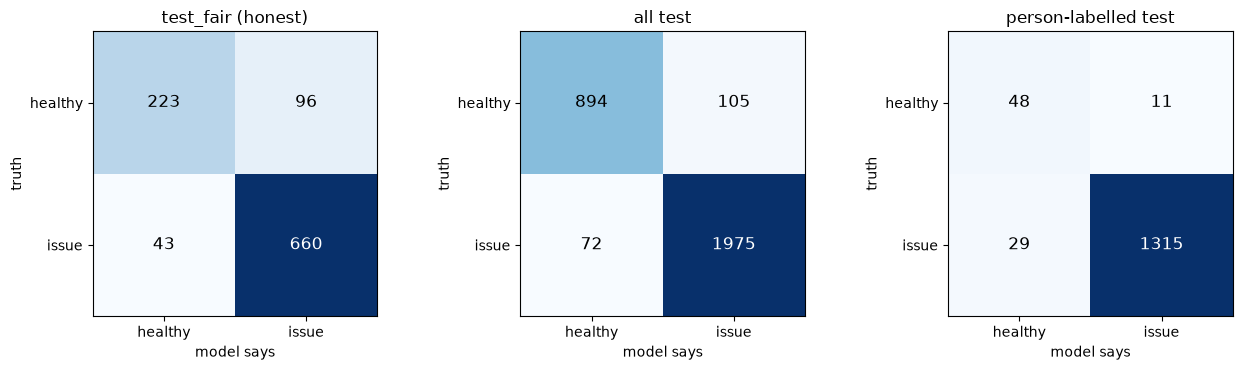

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
panels = [("test_fair (honest)", ym, fair_df.pred.values), ("all test", yt, test_df.pred.values),
          ("person-labelled test", yt[person], test_df.pred.values[person])]
for ax, (name, y_true, y_pred) in zip(axes, panels):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=12)
    ax.set_xticks([0, 1], ["healthy", "issue"]); ax.set_yticks([0, 1], ["healthy", "issue"])
    ax.set_xlabel("model says"); ax.set_ylabel("truth"); ax.set_title(name)
plt.tight_layout(); plt.savefig(FIG_DIR / f"{EXPERIMENT}_confusion.png", dpi=120); plt.show()

## 10. Where does it go wrong? (fairness and error analysis)

- **By source dataset**: the photos come from different collections (different countries, cameras, lighting). A big gap
  between sources is a fairness and generalisation warning for the report. Roboflow and Mendeley have only one class each,
  so only one recall can be computed for them.
- **By condition**: of the test photos that have each condition, how many were flagged? This shows which conditions the
  model tends to miss (e.g. small caries).

In [16]:
rows = []
for (which, src), g in test_df.assign(set="test").groupby(["set", "dataset"]):
    s = scores(g.has_issue.values, g.p_issue.values, threshold)
    rows.append(dict(set=which, source=src, n=s["n"], n_issue=s["n_issue"], n_healthy=s["n_healthy"],
                     recall_issue=s["recall_issue"], recall_healthy=s["recall_healthy"]))
by_source = pd.DataFrame(rows).set_index(["set", "source"])
display(by_source.round(3))

by_condition = pd.DataFrame([
    dict(condition=c, n=int(test_df[c].sum()),
         flagged=float(test_df.loc[test_df[c] == 1, "pred"].mean()) if test_df[c].sum() else float("nan"))
    for c in CONDITIONS]).set_index("condition")
display(by_condition.round(3))

n  n_issue  n_healthy  recall_issue  \
set  source                                                       
test dentalai             455      224        231         0.893   
     external_clean        63       48         15         0.854   
     kaggle_oral          159      100         59         0.900   
     mendeley_noncaries   680        0        680           NaN   
     roboflow_oral       1344     1344          0         0.978   
     zenodo               345      331         14         0.994   

                         recall_healthy  
set  source                              
test dentalai                     0.697  
     external_clean               0.733  
     kaggle_oral                  0.814  
     mendeley_noncaries           0.987  
     roboflow_oral                  NaN  
     zenodo                       0.214

,n,flagged
condition,,
Calculus,278,0.950
Caries,1090,0.974
Hypodontia,185,0.978
Mouth_Ulcer,360,0.981
Tooth_Discoloration,630,0.946


### Missed problems (false negatives) and false alarms

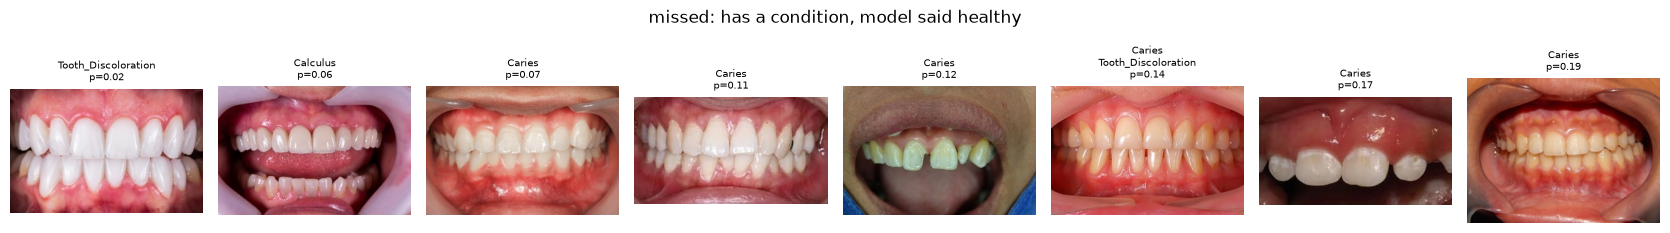

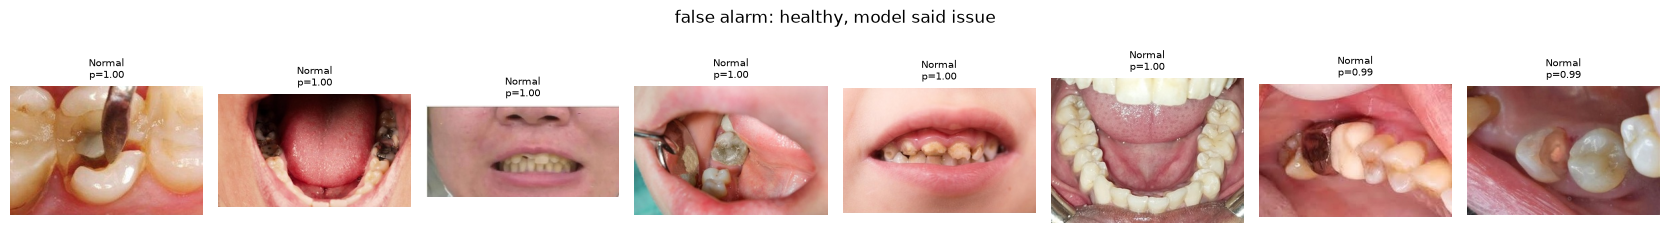

In [17]:
def show(frame, title, n=8):
    frame = frame.head(n)
    if frame.empty:
        print("none:", title); return
    fig, axes = plt.subplots(1, len(frame), figsize=(2.1 * len(frame), 2.6), squeeze=False)
    for ax, (_, r) in zip(axes[0], frame.iterrows()):
        with Image.open(r.cache) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"{str(r['labels']).replace('|', chr(10))}\np={r.p_issue:.2f}", fontsize=7); ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()


show(test_df[(test_df.has_issue == 1) & (test_df.pred == 0)].sort_values("p_issue"), "missed: has a condition, model said healthy")
show(test_df[(test_df.has_issue == 0) & (test_df.pred == 1)].sort_values("p_issue", ascending=False), "false alarm: healthy, model said issue")

## 11. Robustness to poor photos

Patients take photos on phones in bad light. Each test photo is made blurry / dark / overexposed / low-resolution /
heavily compressed, and scored again. A big drop tells us which quality checks the app needs before screening.

In [18]:
rob_df = test_df.sample(min(len(test_df), 1500), random_state=SEED).reset_index(drop=True)
rob = []
for name in [None, *CORRUPTIONS]:
    lg, yr = predict_logits(model, loader(rob_df, eval_tf, corrupt=name))
    s = scores(yr, p_issue(lg, T), threshold)
    rob.append(dict(condition=name or "original", recall_issue=s["recall_issue"],
                    recall_healthy=s["recall_healthy"], balanced_accuracy=s["balanced_accuracy"]))
robustness = pd.DataFrame(rob).set_index("condition")
display(robustness.round(3))

,recall_issue,recall_healthy,balanced_accuracy
condition,,,
original,0.965,0.892,0.929
blur,0.869,0.859,0.864
dark (x0.5),0.955,0.897,0.926
bright (x1.6),0.967,0.847,0.907
low-res (1/3),0.906,0.851,0.879
JPEG q=20,0.956,0.563,0.760


## 12. Save the model and results

- `weights/Brandon/issue_classifier.pt`: weights plus everything needed to use them the same way (image size,
  normalisation, temperature, threshold). Gitignored; share it through the team drive.
- `results/Brandon/`: metrics JSON, training history and one row appended to `experiments.csv`, so the group can
  compare models on the same test set.

In [19]:
ckpt = {
    "task": "issue_or_not",
    "backbone": "efficientnet_b0",
    "head": "classifier.1",
    "classes": ["healthy", "issue"],
    "state_dict": best_state,
    "img_size": IMG_SIZE,
    "mean": MEAN, "std": STD,
    "temperature": T,
    "threshold": threshold,
    "unsure_below": UNSURE_BELOW,
    "config": {"cache_max_side": CACHE_SIDE, "padding_cut_off": True, "epochs_run": int(hist.epoch.max()), "best_epoch": int(best_epoch),
               "batch": BATCH, "lr": LR, "seed": SEED, "dataset": "oral_datasetv1.2 pool (2026-11-14)"},
    "notes": "Screening aid only, not a diagnosis. Stage 1 of 2: says whether any of the five conditions is likely; "
             "stage 2 (YOLO) locates and names them. Gum disease (gingivitis) is not covered.",
}
weights_path = WEIGHTS_DIR / f"{'issue_classifier_v12' + ('_smoke' if SMOKE else '')}.pt"
torch.save(ckpt, weights_path)

metrics = {"experiment": EXPERIMENT, "temperature": T, "threshold": threshold, "best_epoch": int(best_epoch),
           **{k: v for k, v in results.items()},
           "by_source": by_source.reset_index().to_dict("records"),
           "by_condition": by_condition.reset_index().to_dict("records"),
           "robustness": robustness.reset_index().to_dict("records"),
           "cheat_check_size_only_bal_acc": cheat_scores}
(OUT_DIR / f"{EXPERIMENT}_metrics.json").write_text(json.dumps(metrics, indent=2, default=float), encoding="utf-8")
hist.to_csv(OUT_DIR / f"{EXPERIMENT}_history.csv", index=False)

ta, tp_, tm = results["test_all"], results["test_person_only"], results["test_fair"]
row = pd.DataFrame([dict(experiment=EXPERIMENT, date=time.strftime("%Y-%m-%d"), member="Brandon",
                         model="efficientnet_b0", task="issue_or_not", img_size=IMG_SIZE, epochs_run=int(hist.epoch.max()),
                         best_epoch=int(best_epoch), threshold=round(threshold, 4), temperature=round(T, 4),
                         mixed_recall_issue=tm["recall_issue"], mixed_recall_healthy=tm["recall_healthy"],
                         mixed_bal_acc=tm["balanced_accuracy"], mixed_auc=tm["roc_auc"],
                         test_recall_issue=ta["recall_issue"], test_recall_healthy=ta["recall_healthy"],
                         test_bal_acc=ta["balanced_accuracy"], test_auc=ta["roc_auc"],
                         person_recall_issue=tp_["recall_issue"], person_recall_healthy=tp_["recall_healthy"],
                         person_bal_acc=tp_["balanced_accuracy"], weights=str(weights_path.relative_to(REPO)))])
exp_csv = OUT_DIR / "experiments.csv"
row.to_csv(exp_csv, mode="a", header=not exp_csv.exists(), index=False)
print("saved", weights_path.relative_to(REPO), "and results in", OUT_DIR.relative_to(REPO))

saved models\classifier\weights\Brandon\issue_classifier_v12.pt and results in models\classifier\results\Brandon


## 13. Use it on one photo

The same steps the backend will run: open → fix rotation → shrink like the cache (a phone photo has no padding to cut) → resize → normalise → model →
divide by `T` → probability → threshold / "not sure".

In [20]:
from PIL import ImageOps


def screen(path, ckpt=ckpt):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
    im.thumbnail((ckpt["config"]["cache_max_side"],) * 2, Image.LANCZOS)
    x = eval_tf(im)[None].to(device)
    model.eval()
    with torch.no_grad():
        p = float((model(x).float() / ckpt["temperature"]).softmax(1)[0, 1])
    conf = max(p, 1 - p)
    verdict = ("not sure: see a dentist" if conf < ckpt["unsure_below"]
               else "possible issue" if p >= ckpt["threshold"] else "no issue seen")
    return {"p_issue": round(p, 3), "verdict": verdict}


r = test_df.sample(1, random_state=1).iloc[0]
print(r["labels"], "->", screen(r.cache))

Normal -> {'p_issue': 0.124, 'verdict': 'no issue seen'}


## 14. Results at a glance, and what's next

| | test_fair (honest) | all test | person-labelled test |
|---|---|---|---|
| recall: issue | 0.939 | 0.965 | 0.978 |
| recall: healthy | **0.699** | 0.895 | 0.814 (only 59 photos) |
| balanced accuracy | **0.819** | 0.930 | 0.896 |
| ROC-AUC | 0.923 | 0.984 | 0.984 |

Run of 2026-11-14: best epoch 4 of 8 (early stop), T = 1.77, threshold 0.50. Cheat check (size-only rule):
0.87 on test, 0.58 on test_fair. Healthy recall by source: Mendeley 0.99, but DentalAI 0.70, Kaggle 0.81,
Zenodo 0.21 (14 photos). The model recognises Mendeley-style healthy photos much better than healthy photos that
look like the problem sources. That is the remaining shortcut, and the gap between 0.93 and 0.82 shows its size.

**Limitations to state in the report**
- Roboflow is still all problem photos and Mendeley all healthy. The cheat check above shows how much the photo's
  size/shape still reveals; `test_fair` is the score that isn't affected.
- The fair exams are small (a few hundred healthy photos), so their numbers move by a few % between runs.
- The photos are not from Singapore patients; sources differ in camera, lighting and population (see section 10).
- Some training labels come from Qwen, not people; the person-only test score shows how much that matters.
- Gum disease is not one of the classes, so "no issue seen" does not mean a healthy mouth.
- One photo can't show the whole mouth; the app should ask for several angles.

**Next:** stage 2, YOLO on the same split (`pool/data.yaml`, fair exams in `pool/data_fair.yaml`).
